# ITBDA Project 2: Question 2
## News Article Topic Modelling Using Latent Dirichlet Allocation



### Question 2.1: Data Loading and Text Preprocessing
This section's goal is to prepare the news articles textual content for topic modeling by loading them into a structured DataFrame.
Preprocessing will deal with extraneous characters, inconsistent letter casing, stopwords, and other types of noise that could degrade the quality of the topics that were extracted.

In [1]:
import pandas as pd
from pathlib import Path
from zipfile import ZipFile

pd.set_option("display.max_colwidth", 100)

print("Libraries imported.")


Libraries imported.


In [3]:
zip_path = Path("news.zip")

with ZipFile(zip_path, "r") as archive:

    file_names = [
        name for name in archive.namelist()
        if name.lower().endswith(".txt")
    ]

    file_names = sorted(
        file_names,
        key=lambda name: int(Path(name).stem.split("_")[-1])
    )

    records = []

    for file_name in file_names:
        content = archive.read(file_name).decode("utf-8-sig")

        records.append({
            "file_name": Path(file_name).name,
            "content": content
        })

df = pd.DataFrame(records, columns=["file_name", "content"])

print("DataFrame shape:", df.shape)
print("Column names:", df.columns.tolist())

preview = df.copy()
preview["content"] = preview["content"].str.slice(0, 120)

display(preview)


DataFrame shape: (10, 2)
Column names: ['file_name', 'content']


,file_name,content
0,news_1.txt,"Eskom former official, service provider appear in court\r\nTuesday, July 9, 2024\r\n\r\nAn Eskom..."
1,news_2.txt,"Gauteng Education commits to implementing Mayibuye Primary School remedial actions\r\nTuesday, J..."
2,news_3.txt,"New Labour Minister charts the way forward \r\nTuesday, July 9, 2024\r\n\r\nNewly appointed Empl..."
3,news_4.txt,"Police recue two kidnapped victims in Benoni\r\nTuesday, July 9, 2024\r\n\r\nSwift and agile act..."
4,news_5.txt,"President Ramaphosa sends condolences to deceased SANDF members\r\nTuesday, July 9, 2024\r\n\r\n..."
5,news_6.txt,"Accounting officers must be accountable for non-payment of service providers\r\nMonday, July 8, ..."
6,news_7.txt,"Democratic dispensation necessitated a complete overhaul of state bureaucracy\r\nMonday, July 8,..."
7,news_8.txt,"Trust and relationships key ingredients to coalition governments\r\nMonday, July 8, 2024\r\n\r\n..."
8,news_9.txt,"PSC applauds officials who refuse to accept a bribes\r\nMonday, July 8, 2024\r\n\r\nThe Public S..."
9,news_10.txt,"Wet, cold weather expected to continue in Western Cape\r\nMonday, July 8, 2024\r\n\r\nCold and w..."


### Data Quality check


In [4]:
print("Dataset shape:", df.shape)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate filenames:")
print(df["file_name"].duplicated().sum())

print("\nDuplicate article content:")
print(df["content"].duplicated().sum())

print("\nEmpty articles:")
print(df["content"].str.strip().eq("").sum())

df["original_word_count"] = df["content"].str.split().str.len()

display(df[["file_name", "original_word_count"]])


Dataset shape: (10, 2)

Missing values:
file_name    0
content      0
dtype: int64

Duplicate filenames:
0

Duplicate article content:
0

Empty articles:
0


,file_name,original_word_count
0,news_1.txt,237
1,news_2.txt,285
2,news_3.txt,633
3,news_4.txt,215
4,news_5.txt,257
5,news_6.txt,450
6,news_7.txt,241
7,news_8.txt,720
8,news_9.txt,349
9,news_10.txt,445


### Text Preprocessing

In [5]:
import re
import html
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

stop_words = set(ENGLISH_STOP_WORDS)

def preprocess_text(text):

    if pd.isna(text):
        return ""

    text = html.unescape(str(text))

    text = text.lower()

    text = re.sub(r"\\r\\n|\\n|\\r|\r\n|\r|\n", " ", text)

    text = re.sub(r"https?://\S+|www\.\S+", " ", text)

    text = re.sub(r"[^a-z\s]", " ", text)

    tokens = re.findall(r"\b[a-z]{3,}\b", text)

    tokens = [
        word for word in tokens
        if word not in stop_words
    ]

    return " ".join(tokens)

df["clean_content"] = df["content"].apply(preprocess_text)

df["clean_word_count"] = (
    df["clean_content"].str.split().str.len()
)

display(df[
    ["file_name", "original_word_count",
     "clean_word_count", "clean_content"]
])


,file_name,original_word_count,clean_word_count,clean_content
0,news_1.txt,237,129,eskom official service provider appear court tuesday july eskom employee service provider power ...
1,news_2.txt,285,158,gauteng education commits implementing mayibuye primary school remedial actions tuesday july gau...
2,news_3.txt,633,347,new labour minister charts way forward tuesday july newly appointed employment labour minister n...
3,news_4.txt,215,120,police recue kidnapped victims benoni tuesday july swift agile action south african police servi...
4,news_5.txt,257,132,president ramaphosa sends condolences deceased sandf members tuesday july president cyril ramaph...
5,news_6.txt,450,237,accounting officers accountable non payment service providers monday july accounting officers he...
6,news_7.txt,241,150,democratic dispensation necessitated complete overhaul state bureaucracy monday july public serv...
7,news_8.txt,720,402,trust relationships key ingredients coalition governments monday july advisor coalition governme...
8,news_9.txt,349,202,psc applauds officials refuse accept bribes monday july public service commission psc applauded ...
9,news_10.txt,445,247,wet cold weather expected continue western cape monday july cold wet weather expected continue w...


In [6]:
date_words = {
    "monday", "tuesday", "wednesday", "thursday",
    "friday", "saturday", "sunday",
    "january", "february", "march", "april",
    "may", "june", "july", "august",
    "september", "october", "november", "december"
}

stop_words.update(date_words)

df["clean_content"] = df["content"].apply(preprocess_text)

df["clean_word_count"] = (
    df["clean_content"].str.split().str.len()
)

display(df[["file_name", "clean_word_count", "clean_content"]])


,file_name,clean_word_count,clean_content
0,news_1.txt,124,eskom official service provider appear court eskom employee service provider power utility appea...
1,news_2.txt,155,gauteng education commits implementing mayibuye primary school remedial actions gauteng departme...
2,news_3.txt,344,new labour minister charts way forward newly appointed employment labour minister nomakhosazana ...
3,news_4.txt,115,police recue kidnapped victims benoni swift agile action south african police service saps elite...
4,news_5.txt,129,president ramaphosa sends condolences deceased sandf members president cyril ramaphosa sent cond...
5,news_6.txt,233,accounting officers accountable non payment service providers accounting officers held accountab...
6,news_7.txt,148,democratic dispensation necessitated complete overhaul state bureaucracy public service commissi...
7,news_8.txt,399,trust relationships key ingredients coalition governments advisor coalition governments ireland ...
8,news_9.txt,200,psc applauds officials refuse accept bribes public service commission psc applauded officials re...
9,news_10.txt,242,wet cold weather expected continue western cape cold wet weather expected continue western cape ...


## Question 2.2: Latent Dirichlet Allocation (LDA)

In [7]:
from sklearn.feature_extraction.text import CountVectorizer

vectorizer = CountVectorizer(
    min_df=1,
    max_df=0.9,
    token_pattern=r"(?u)\b[a-z]{3,}\b"
)

dtm = vectorizer.fit_transform(df["clean_content"])

feature_names = vectorizer.get_feature_names_out()

print("Number of documents:", dtm.shape[0])
print("Number of unique terms:", dtm.shape[1])
print("Document-term matrix shape:", dtm.shape)

dtm_df = pd.DataFrame(
    dtm.toarray(),
    columns=feature_names,
    index=df["file_name"]
)

display(dtm_df.iloc[:5, :10])


Number of documents: 10
Number of unique terms: 1038
Document-term matrix shape: (10, 1038)


,abandoned,abroad,accept,acceptance,access,according,accountability,accountable,accounting,achieved
file_name,,,,,,,,,,
news_1.txt,0,0,0,0,0,1,0,1,0,0
news_2.txt,0,0,0,0,0,1,0,0,0,0
news_3.txt,0,0,0,0,0,1,0,0,0,1
news_4.txt,0,0,0,0,0,1,0,0,0,0
news_5.txt,1,0,0,0,0,0,0,0,0,0


### LDA Model Training

In [8]:
from sklearn.decomposition import LatentDirichletAllocation

n_topics = 3

lda_model = LatentDirichletAllocation(
    n_components=n_topics,
    max_iter=100,
    learning_method="batch",
    random_state=42
)
doc_topic_matrix = lda_model.fit_transform(dtm)

print("LDA model trained successfully.")
print("Number of topics:", n_topics)
print("Number of documents:", doc_topic_matrix.shape[0])
print("Document-topic matrix shape:", doc_topic_matrix.shape)


LDA model trained successfully.
Number of topics: 3
Number of documents: 10
Document-topic matrix shape: (10, 3)


### Topic-Word Distribution

In [9]:
top_k = 10
topic_word_probs = (
    lda_model.components_
    / lda_model.components_.sum(axis=1, keepdims=True)
)

topic_records = []

for topic_idx, word_probs in enumerate(topic_word_probs):
    top_indices = word_probs.argsort()[::-1][:top_k]

    for rank, word_idx in enumerate(top_indices, start=1):
        topic_records.append({
            "Topic": f"Topic {topic_idx + 1}",
            "Rank": rank,
            "Word": feature_names[word_idx],
            "Probability": word_probs[word_idx]
        })

topic_words_df = pd.DataFrame(topic_records)
display(
    topic_words_df.style.format({
        "Probability": "{:.4f}"
    })
)


,Topic,Rank,Word,Probability
0,Topic 1,1,government,0.0135
1,Topic 1,2,public,0.0135
2,Topic 1,3,coalition,0.0110
3,Topic 1,4,administration,0.0102
4,Topic 1,5,department,0.0093
5,Topic 1,6,africa,0.0077
6,Topic 1,7,governments,0.0077
7,Topic 1,8,national,0.0069
8,Topic 1,9,south,0.0069
9,Topic 1,10,unemployment,0.0069


### Topic Distribution

In [10]:
doc_topics_df = pd.DataFrame(
    doc_topic_matrix,
    columns=[f"Topic {i+1}" for i in range(n_topics)]
)
doc_topics_df.insert(0, "file_name", df["file_name"].values)
topic_columns = [f"Topic {i+1}" for i in range(n_topics)]

doc_topics_df["Dominant Topic"] = (
    doc_topics_df[topic_columns].idxmax(axis=1)
)
doc_topics_df["Dominant Probability"] = (
    doc_topics_df[topic_columns].max(axis=1)
)
display(
    doc_topics_df.style.format({
        "Topic 1": "{:.4f}",
        "Topic 2": "{:.4f}",
        "Topic 3": "{:.4f}",
        "Dominant Probability": "{:.4f}"
    })
)
print("\nDocuments per dominant topic:")

print(
    doc_topics_df["Dominant Topic"]
    .value_counts()
    .sort_index()
)
print("\nTopic probability sums:")
print(doc_topic_matrix.sum(axis=1).round(4))


,file_name,Topic 1,Topic 2,Topic 3,Dominant Topic,Dominant Probability
0,news_1.txt,0.0028,0.9943,0.0029,Topic 2,0.9943
1,news_2.txt,0.0023,0.9955,0.0022,Topic 2,0.9955
2,news_3.txt,0.9980,0.0010,0.0010,Topic 1,0.9980
3,news_4.txt,0.0030,0.0031,0.9940,Topic 3,0.9940
4,news_5.txt,0.0027,0.0027,0.9946,Topic 3,0.9946
5,news_6.txt,0.0015,0.9970,0.0015,Topic 2,0.9970
6,news_7.txt,0.9950,0.0026,0.0024,Topic 1,0.9950
7,news_8.txt,0.9982,0.0009,0.0009,Topic 1,0.9982
8,news_9.txt,0.0019,0.9964,0.0018,Topic 2,0.9964
9,news_10.txt,0.0015,0.0015,0.9971,Topic 3,0.9971



Documents per dominant topic:
Dominant Topic
Topic 1    3
Topic 2    4
Topic 3    3
Name: count, dtype: int64

Topic probability sums:
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


## Question 2.3: LDA Topic Visualizations

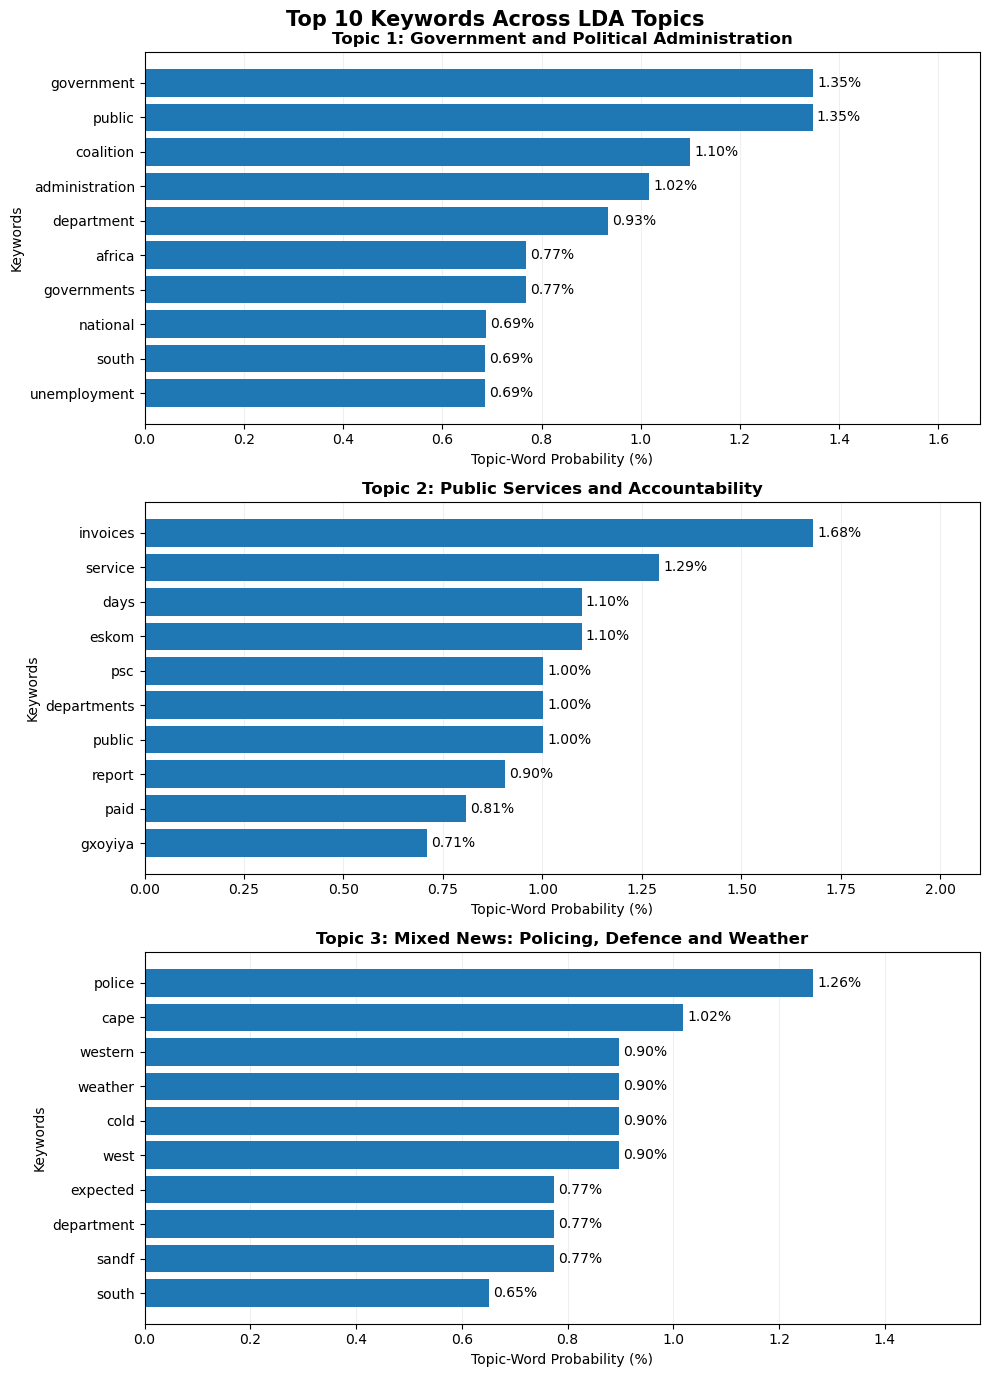

Bar charts saved successfully.


In [11]:
import matplotlib.pyplot as plt
from pathlib import Path

output_dir = Path("Question2_Figures")
output_dir.mkdir(exist_ok=True)

topic_labels = {
    "Topic 1": "Government and Political Administration",
    "Topic 2": "Public Services and Accountability",
    "Topic 3": "Mixed News: Policing, Defence and Weather"
}
fig, axes = plt.subplots(
    nrows=3,
    ncols=1,
    figsize=(10, 14)
)

for i in range(n_topics):

    topic_name = f"Topic {i + 1}"
    topic_data = topic_words_df[
        topic_words_df["Topic"] == topic_name
    ].sort_values("Probability", ascending=True)
    percentages = topic_data["Probability"] * 100

    ax = axes[i]

    bars = ax.barh(
        topic_data["Word"],
        percentages
    )
    ax.bar_label(
        bars,
        labels=[f"{p:.2f}%" for p in percentages],
        padding=3
    )

    ax.set_title(
        f"{topic_name}: {topic_labels[topic_name]}",
        fontsize=12,
        fontweight="bold"
    )

    ax.set_xlabel("Topic-Word Probability (%)")
    ax.set_ylabel("Keywords")

    ax.set_xlim(0, percentages.max() * 1.25)

    ax.grid(axis="x", alpha=0.2)
    ax.set_axisbelow(True)

fig.suptitle(
    "Top 10 Keywords Across LDA Topics",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    output_dir / "LDA_Top_Words_Bar_Charts.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
print("Bar charts saved successfully.")

### Topic-Word Probability Heatmap

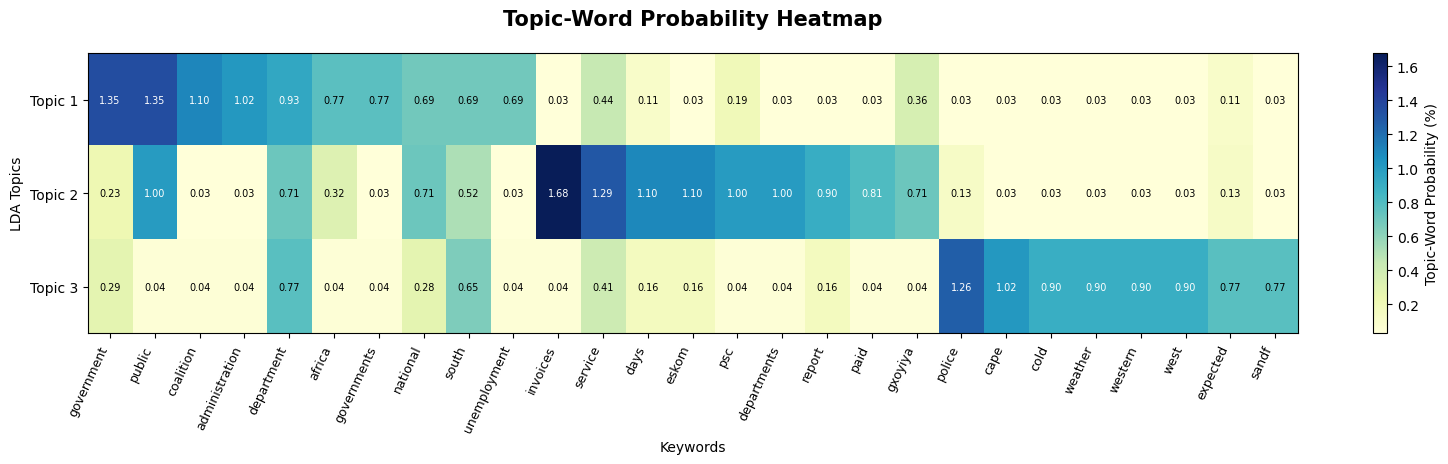

Heatmap saved successfully.


In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

selected_indices = []
seen_indices = set()

for topic_idx in range(n_topics):

    top_indices = (
        topic_word_probs[topic_idx]
        .argsort()[::-1][:top_k]
    )

    for word_idx in top_indices:
        word_idx = int(word_idx)

        if word_idx not in seen_indices:
            selected_indices.append(word_idx)
            seen_indices.add(word_idx)
selected_words = feature_names[selected_indices]

heatmap_data = pd.DataFrame(
    topic_word_probs[:, selected_indices] * 100,
    index=[f"Topic {i+1}" for i in range(n_topics)],
    columns=selected_words
)

fig, ax = plt.subplots(
    figsize=(max(15, len(selected_words) * 0.6), 5)
)

im = ax.imshow(
    heatmap_data.values,
    aspect="auto",
    cmap="YlGnBu"
)

ax.set_xticks(np.arange(len(selected_words)))
ax.set_xticklabels(
    selected_words,
    rotation=65,
    ha="right",
    fontsize=9
)

ax.set_yticks(np.arange(n_topics))
ax.set_yticklabels(heatmap_data.index)

ax.set_xlabel("Keywords")
ax.set_ylabel("LDA Topics")

ax.set_title(
    "Topic-Word Probability Heatmap",
    fontsize=15,
    fontweight="bold",
    pad=20
)

for i in range(n_topics):
    for j in range(len(selected_words)):

        probability = heatmap_data.iloc[i, j]

        ax.text(
            j, i,
            f"{probability:.2f}",
            ha="center",
            va="center",
            fontsize=7,
            color="white" if probability > 0.8 else "black"
        )

cbar = fig.colorbar(im, ax=ax)
cbar.set_label("Topic-Word Probability (%)")

plt.tight_layout(rect=[0, 0, 1, 0.95])

plt.savefig(
    output_dir / "LDA_Topic_Word_Heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Heatmap saved successfully.")

### Interpretation of LDA Visualizations

The LDA model identified three main topic groups across the ten news articles.

**Topic 1: Government and Political Administration**

With a probability of 1.35%, "government" and "public" were the most powerful keywords, followed by "coalition" (1.10%) and "administration" (1.02%). These terms imply that the subject is primarily concerned with public affairs, political administration, and government operations.

**Topic 2: Public Services and Accountability**

At 1.68%, "invoices" had the highest probability, followed by "service" (1.29%), "days" (1.10%), and "eskom" (1.10%). This subject seems to center on accountability in public institutions, payment procedures, and service delivery.

**Topic 3: Mixed News Topics**

At 1.26%, "Police" was the most significant keyword, followed by "cape" (1.02%). Words with probabilities of 0.90% included "cold," "weather," and "western." The topic blends news about weather, law enforcement, and defense, indicating that the model did not completely distinguish these various topics.

**Comparison of the Visualizations**

It is simple to determine the primary keywords because the horizontal bar charts clearly display the ten words with the highest probability within each topic.

The heatmap offers a comparison for each of the three subjects. Its color intensity aids in identifying common keywords and draws attention to variations in the likelihood of individual words.

**Limitations**
There are only ten documents in the dataset, despite the model assigning each article to a dominant topic. This reduces the clarity with which LDA can identify various themes. Therefore, rather than creating precise news categories, the results are helpful for investigating general trends.


In [14]:
df.to_csv(
    "ITBDA_Cleaned_News.csv",
    index=False,
    encoding="utf-8-sig"
)
topic_words_df.to_csv(
    "LDA_Topic_Word_Probabilities.csv",
    index=False
)
doc_topics_df.to_csv(
    "LDA_Document_Topic_Distribution.csv",
    index=False
)

print("All Question 2 result saved successfully.")


All Question 2 result saved successfully.
